In [2]:
import pandas as pd
df = pd.read_csv("weight.csv")

In [3]:
df

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801
...,...,...,...
9995,Female,66.172652,136.777454
9996,Female,67.067155,170.867906
9997,Female,63.867992,128.475319
9998,Female,69.034243,163.852461


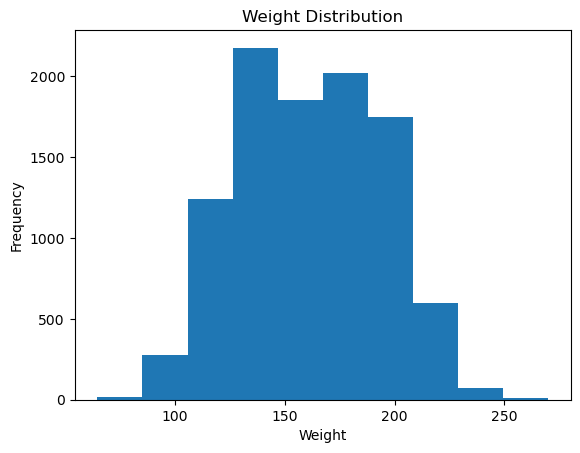

In [13]:
import matplotlib.pyplot as plt

import pandas as pd
df = pd.read_csv("weight.csv")
plt.hist(df["Weight"], bins=10)
plt.xlabel("Weight")
plt.ylabel("Frequency")
plt.title("Weight Distribution")
plt.show()

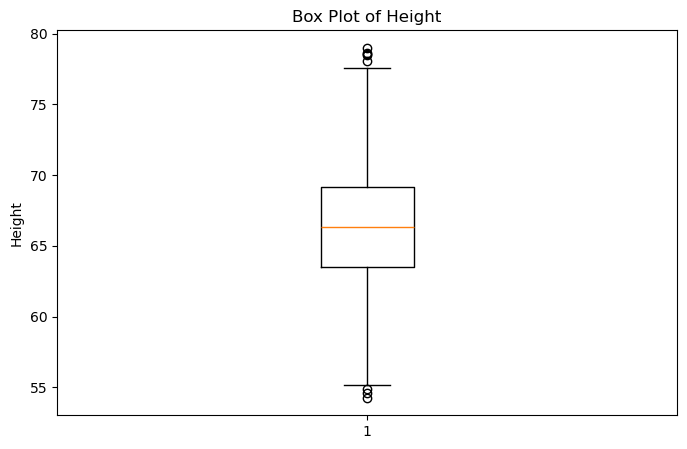

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("weight.csv")
plt.figure(figsize=(8, 5))

plt.boxplot(df['Height'].dropna())

plt.title("Box Plot of Height")
plt.ylabel("Height")

plt.show()

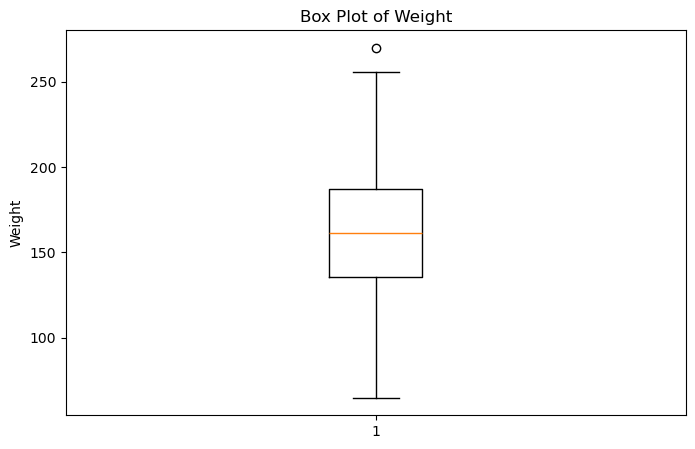

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("weight.csv")
plt.figure(figsize=(8, 5))

plt.boxplot(df['Weight'].dropna())

plt.title("Box Plot of Weight")
plt.ylabel("Weight")

plt.show()

In [18]:
import pandas as pd
import numpy as np
df = pd.read_csv("weight.csv")
Q1 = df['Height'].quantile(0.25)
Q2 = df['Weight'].quantile(0.25)
print(Q1)
print(Q2)

63.505620481218955
135.8180513055015


In [19]:
import pandas as pd
import numpy as np
df = pd.read_csv("weight.csv")
Q1 = df['Height'].quantile(0.75)
Q2 = df['Weight'].quantile(0.75)
print(Q1)
print(Q2)

69.1742617268347
187.16952486868348


In [20]:
import pandas as pd
import numpy as np
df = pd.read_csv("weight.csv")
Q1 = df['Height'].quantile(0.25)
Q2 = df['Height'].quantile(0.75)
print("IQR=",Q2-Q1)

IQR= 5.668641245615746


In [21]:
import pandas as pd
import numpy as np
df = pd.read_csv("weight.csv")
Q1 = df['Height'].quantile(0.25)
Q2 = df['Height'].quantile(0.75)
IQR = Q2-Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q2 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

Lower Limit = 55.00265861279534
Upper Limit = 77.67722359525831


In [22]:
outliers_iqr = df[
(df["Height"] < lower_limit) |
(df["Weight"] > upper_limit)
]

print("Outliers detected using IQR")
print(outliers_iqr)

Outliers detected using IQR
      Gender     Height      Weight
0       Male  73.847017  241.893563
1       Male  68.781904  162.310473
2       Male  74.110105  212.740856
3       Male  71.730978  220.042470
4       Male  69.881796  206.349801
...      ...        ...         ...
9995  Female  66.172652  136.777454
9996  Female  67.067155  170.867906
9997  Female  63.867992  128.475319
9998  Female  69.034243  163.852461
9999  Female  61.944246  113.649103

[9997 rows x 3 columns]


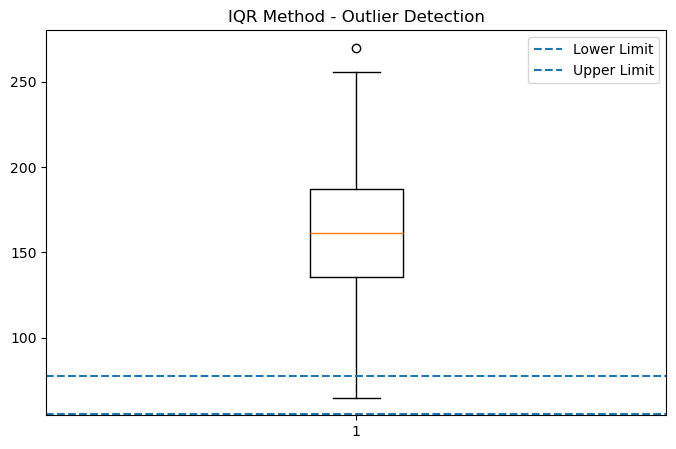

In [23]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['Weight'].dropna())

plt.axhline(lower_limit, linestyle="--", label="Lower Limit")
plt.axhline(upper_limit, linestyle="--", label="Upper Limit")

plt.title("IQR Method - Outlier Detection")
plt.legend()

plt.show()

In [24]:
df["Height_IQR_Capped"] = df["Height"].clip(
lower=lower_limit,
upper=upper_limit
)

print(df[["Height", "Height_IQR_Capped"]])

         Height  Height_IQR_Capped
0     73.847017          73.847017
1     68.781904          68.781904
2     74.110105          74.110105
3     71.730978          71.730978
4     69.881796          69.881796
...         ...                ...
9995  66.172652          66.172652
9996  67.067155          67.067155
9997  63.867992          63.867992
9998  69.034243          69.034243
9999  61.944246          61.944246

[10000 rows x 2 columns]


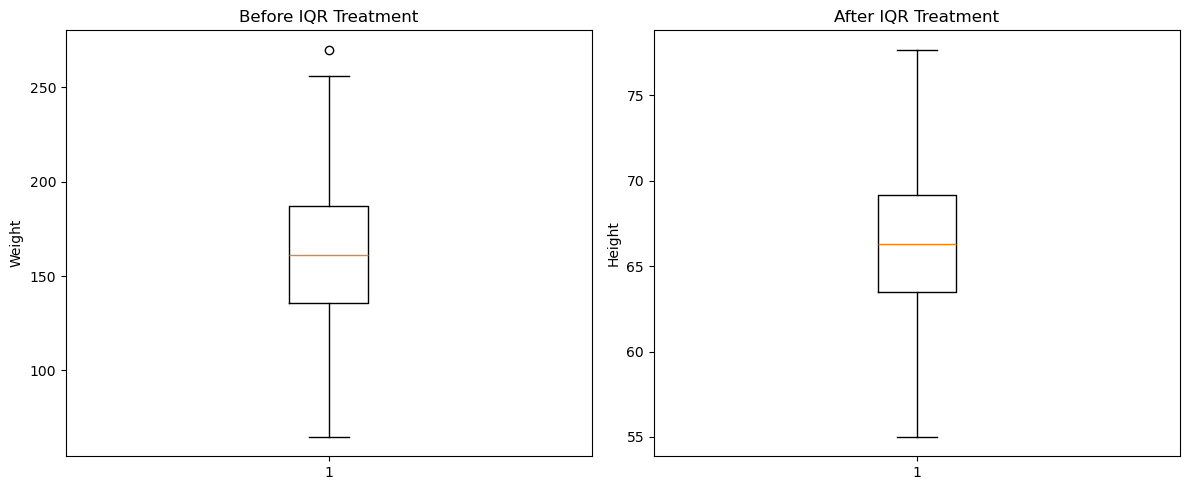

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].boxplot(df['Weight'].dropna())
axes[0].set_title("Before IQR Treatment")
axes[0].set_ylabel("Weight")

axes[1].boxplot(df['Height_IQR_Capped'].dropna())
axes[1].set_title("After IQR Treatment")
axes[1].set_ylabel("Height")

plt.tight_layout()
plt.show()

In [27]:
from scipy import stats
df["Z_score"] = stats.zscore(df["Height"])

print(df[["Height", "Z_score"]])

         Height   Z_score
0     73.847017  1.944061
1     68.781904  0.627537
2     74.110105  2.012443
3     71.730978  1.394060
4     69.881796  0.913421
...         ...       ...
9995  66.172652 -0.050660
9996  67.067155  0.181839
9997  63.867992 -0.649688
9998  69.034243  0.693125
9999  61.944246 -1.149708

[10000 rows x 2 columns]


In [28]:
z_outliers = df[abs(df["Z_score"]) > 3]

print("Outliers detected using Z-score:")
print(z_outliers)

Outliers detected using Z-score:
      Gender     Height      Weight  Height_IQR_Capped   Z_score
994     Male  78.095867  255.690835          77.677224  3.048423
1317    Male  78.462053  227.342565          77.677224  3.143602
2014    Male  78.998742  269.989699          77.677224  3.283099
3285    Male  78.528210  253.889004          77.677224  3.160798
3757    Male  78.621374  245.733783          77.677224  3.185013
6624  Female  54.616858   71.393749          55.002659 -3.054244
9285  Female  54.263133   64.700127          55.002659 -3.146184


In [29]:
df["Z_Outlier"] = abs(df["Z_score"])> 3

print(df[["Height","Z_score", "Z_Outlier"]])

         Height   Z_score  Z_Outlier
0     73.847017  1.944061      False
1     68.781904  0.627537      False
2     74.110105  2.012443      False
3     71.730978  1.394060      False
4     69.881796  0.913421      False
...         ...       ...        ...
9995  66.172652 -0.050660      False
9996  67.067155  0.181839      False
9997  63.867992 -0.649688      False
9998  69.034243  0.693125      False
9999  61.944246 -1.149708      False

[10000 rows x 3 columns]


In [30]:
mean = df["Height"].mean()
std = df["Weight"].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

Lower Z-score limit = -29.957757264737538
Upper Z-score limit = 162.69287677438


In [31]:
df["Height_Z_Capped"] = df["Height"].clip(
lower=lower_z_limit,
upper=upper_z_limit
)

print(df[["Height","Height_Z_Capped"]])

         Height  Height_Z_Capped
0     73.847017        73.847017
1     68.781904        68.781904
2     74.110105        74.110105
3     71.730978        71.730978
4     69.881796        69.881796
...         ...              ...
9995  66.172652        66.172652
9996  67.067155        67.067155
9997  63.867992        63.867992
9998  69.034243        69.034243
9999  61.944246        61.944246

[10000 rows x 2 columns]


In [32]:
print(df[["Height",
"Height_IQR_Capped",
"Height_Z_Capped"]])

         Height  Height_IQR_Capped  Height_Z_Capped
0     73.847017          73.847017        73.847017
1     68.781904          68.781904        68.781904
2     74.110105          74.110105        74.110105
3     71.730978          71.730978        71.730978
4     69.881796          69.881796        69.881796
...         ...                ...              ...
9995  66.172652          66.172652        66.172652
9996  67.067155          67.067155        67.067155
9997  63.867992          63.867992        63.867992
9998  69.034243          69.034243        69.034243
9999  61.944246          61.944246        61.944246

[10000 rows x 3 columns]


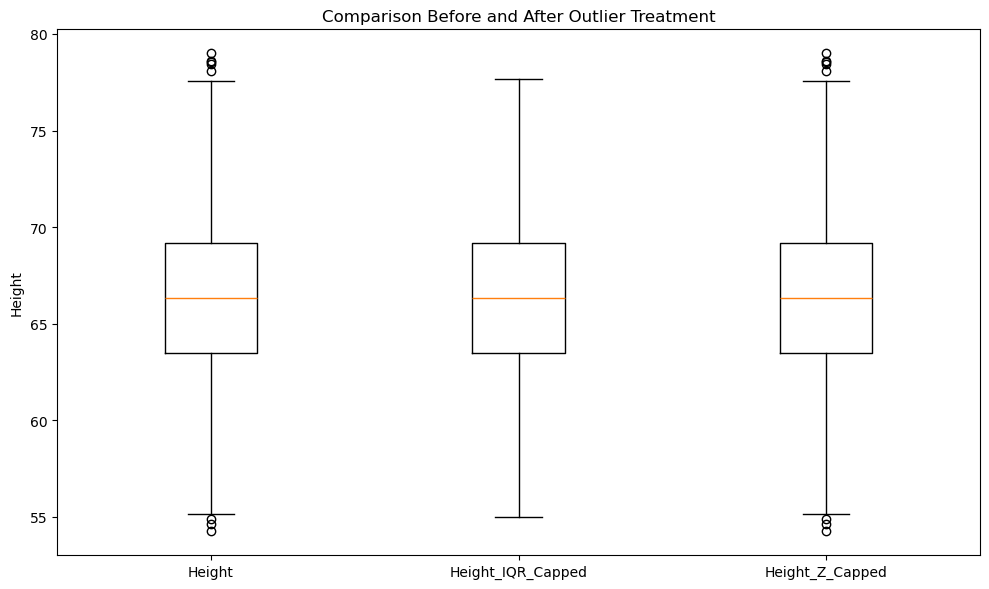

In [33]:
plt.figure(figsize=(10, 6))

plt.boxplot([
    df['Height'].dropna(),
    df['Height_IQR_Capped'].dropna(),
    df['Height_Z_Capped'].dropna()
])

plt.xticks(
    [1, 2, 3],
    ['Height', 'Height_IQR_Capped', 'Height_Z_Capped']
)

plt.title("Comparison Before and After Outlier Treatment")
plt.ylabel("Height")

plt.tight_layout()
plt.show()